In [ ]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

# Lab 01 - Regression

## 1. Implement from scratch

### 1.1. Simple Linear Regression

In [ ]:
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 2, 1.3, 3.75, 2.25])
print("X:", X)
print("y:", y)

X: [[1]
 [2]
 [3]
 [4]
 [5]]
y: [1.   2.   1.3  3.75 2.25]


In [ ]:
class SimpleLinearRegression:
    """Simple Linear Regression using the Ordinary Least Squares (OLS) method."""

    def __init__(self):
        self.slope = None       # coefficient (m)
        self.intercept = None   # y-intercept (b)

    def fit(self, X, y):
        # Flatten X to a 1D array (in case it comes as shape (n, 1))
        x = X.flatten()
        n = len(x)
        # OLS formulas:
        #   slope = (n*Σxy - Σx*Σy) / (n*Σx² - (Σx)²)
        #   intercept = (Σy - slope*Σx) / n
        numerator   = n * np.sum(x * y) - np.sum(x) * np.sum(y)
        denominator = n * np.sum(x ** 2) - np.sum(x) ** 2
        self.slope = numerator / denominator
        self.intercept = (np.sum(y) - self.slope * np.sum(x)) / n
        return self

    def predict(self, X):
        x = X.flatten()
        return self.slope * x + self.intercept

In [ ]:
# Fit the model and make predictions
slr = SimpleLinearRegression()
slr.fit(X, y)
y_pred = slr.predict(X)

print(f"Slope (m):     {slr.slope:.4f}")
print(f"Intercept (b): {slr.intercept:.4f}")
print(f"Equation:      y = {slr.slope:.4f} * x + {slr.intercept:.4f}")
print("\nActual vs Predicted:")
for a, p in zip(y, y_pred):
    print(f"  actual={a:.2f}  predicted={p:.4f}")


Slope (m):     0.4250
Intercept (b): 0.7850
Equation:      y = 0.4250 * x + 0.7850

Actual vs Predicted:
  actual=1.00  predicted=1.2100
  actual=2.00  predicted=1.6350
  actual=1.30  predicted=2.0600
  actual=3.75  predicted=2.4850
  actual=2.25  predicted=2.9100


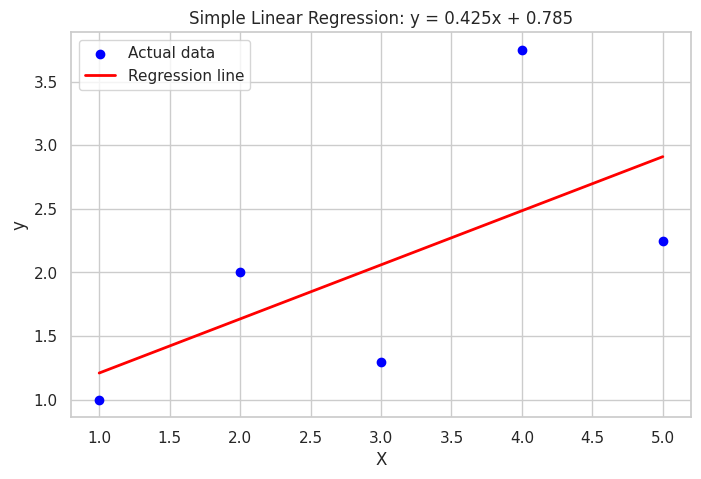

In [ ]:
# Scatter plot of the data + fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X.flatten(), y, color='blue', label='Actual data')
plt.plot(X.flatten(), y_pred, color='red', linewidth=2, label='Regression line')
plt.xlabel('X')
plt.ylabel('y')
plt.title(f'Simple Linear Regression: y = {slr.slope:.3f}x + {slr.intercept:.3f}')
plt.legend()
plt.grid(True)
plt.show()

### 1.2 Multiple Linear Regression

In [ ]:
X = np.array(
    [
        [1,1,1],
        [1,1,2],
        [1,2,2],
        [1,0,1]
    ]
)

Y = np.array([
    3.25,
    6.5,
    3.5,
    5.0
])

In [ ]:
class MultipleLinearRegression:
    """Multiple Linear Regression using the Normal Equation: θ = (XᵀX)⁻¹ Xᵀy"""

    def __init__(self):
        self.coefficients = None

    def fit(self, X, y):
        # Normal equation — X already contains a column of ones for the intercept
        XtX = X.T @ X
        Xty = X.T @ y
        self.coefficients = np.linalg.inv(XtX) @ Xty
        return self

    def predict(self, X):
        return X @ self.coefficients

In [ ]:
# Fit the model and print learned coefficients
mlr = MultipleLinearRegression()
mlr.fit(X, Y)
Y_pred = mlr.predict(X)

print("Learned coefficients [bias, β1, β2, β3]:")
print(np.round(mlr.coefficients, 4))

print("\nActual vs Predicted:")
for a, p in zip(Y, Y_pred):
    print(f"  actual={a:.2f}  predicted={p:.4f}")

Learned coefficients [bias, β1, β2, β3]:
[ 2.0625 -2.375   3.25  ]

Actual vs Predicted:
  actual=3.25  predicted=2.9375
  actual=6.50  predicted=6.1875
  actual=3.50  predicted=3.8125
  actual=5.00  predicted=5.3125


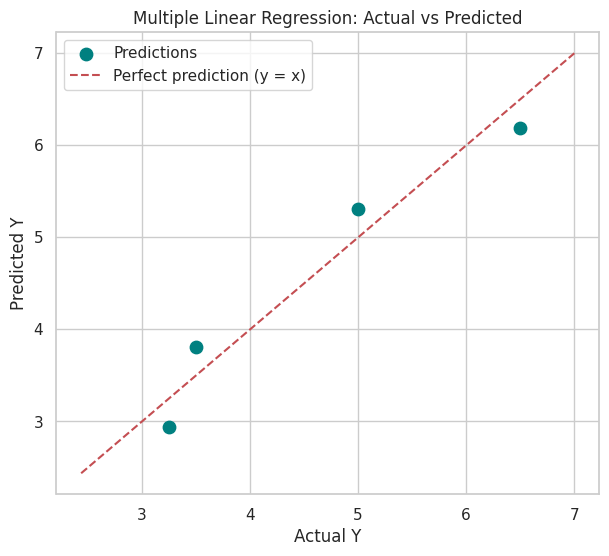

In [ ]:
# Predicted vs Actual scatter — points near the diagonal mean good fit
plt.figure(figsize=(7, 6))
plt.scatter(Y, Y_pred, color='teal', s=80, label='Predictions')

# y = x reference line (perfect prediction)
lims = [min(Y.min(), Y_pred.min()) - 0.5, max(Y.max(), Y_pred.max()) + 0.5]
plt.plot(lims, lims, 'r--', label='Perfect prediction (y = x)')

plt.xlabel('Actual Y')
plt.ylabel('Predicted Y')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

### 1.3 Gradient Descent

In [ ]:
def gradient_descent(starting_point, gradient_func, learning_rate, max_iter, tolerance):
    x = starting_point
    history = [x]
    for _ in range(max_iter):
        grad = gradient_func(x)
        x_new = x - learning_rate * grad
        history.append(x_new)
        if abs(x_new - x) < tolerance:
            x = x_new
            break
        x = x_new
    return history, x

In [ ]:
def func(x):
    return x**2 - 4*x + 1

def grad_func(x):
    return 2*x - 4


Optimized result: 1.976941569907863


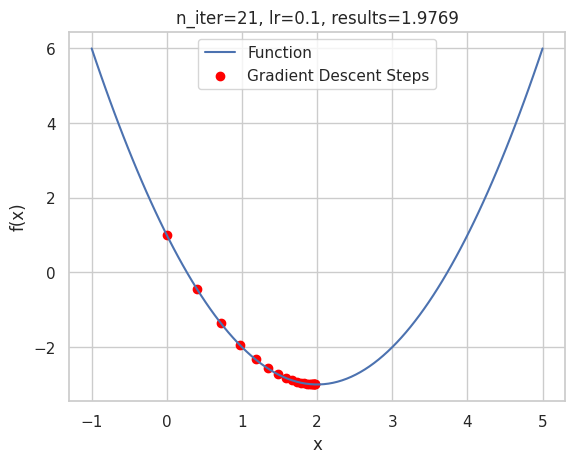

In [ ]:
lr = 0.1

history, result = gradient_descent(
    starting_point=0.0,
    gradient_func=grad_func,
    learning_rate=lr,
    max_iter=20,
    tolerance=1e-6
)
print("Optimized result:", result)

history_array = np.array(history)
x_vals = np.linspace(-1, 5, 100)
y_vals = func(x_vals)

plt.plot(x_vals, y_vals, label='Function')
plt.scatter(history_array, func(history_array), color='red', label='Gradient Descent Steps')
plt.legend()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(f'n_iter={len(history)}, lr={lr}, results={result:.4f}')

plt.show()

## 2. Using scikit-learn

### 2.1. Load dataset

- In this lab, we use dataset [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (id=9).
- We want to predict Miles Per Gallon (MPG) - a measure of a vehicle's fuel efficiency. It shows how many miles a car can travel on one gallon of fuel. A higher MPG means a car is more fuel-efficient, travels further on less fuel, and can result in lower running costs.

In [ ]:
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    !pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo

In [ ]:

# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# data (as pandas dataframes)
X = auto_mpg.data.features
y = auto_mpg.data.targets

In [ ]:
auto_mpg.metadata

{'uci_id': 9,
 'name': 'Auto MPG',
 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg',
 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv',
 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption',
 'area': 'Other',
 'tasks': ['Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 398,
 'num_features': 7,
 'feature_types': ['Real', 'Categorical', 'Integer'],
 'demographics': [],
 'target_col': ['mpg'],
 'index_col': ['car_name'],
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 1993,
 'last_updated': 'Thu Aug 10 2023',
 'dataset_doi': '10.24432/C5859H',
 'creators': ['R. Quinlan'],
 'intro_paper': None,
 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had 

In [ ]:
auto_mpg.variables

,name,role,type,demographic,description,units,missing_values
0,displacement,Feature,Continuous,None,None,None,no
1,mpg,Target,Continuous,None,None,None,no
2,cylinders,Feature,Integer,None,None,None,no
3,horsepower,Feature,Continuous,None,None,None,yes
4,weight,Feature,Continuous,None,None,None,no
5,acceleration,Feature,Continuous,None,None,None,no
6,model_year,Feature,Integer,None,None,None,no
7,origin,Feature,Integer,None,None,None,no
8,car_name,ID,Categorical,None,None,None,no


In [ ]:
X.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [ ]:
y.head()

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


### 2.2. EDA

#### General sanity check

In [ ]:
# Combine features and target into a single DataFrame for EDA
df = pd.concat([X, y], axis=1)

In [ ]:
df.isna().sum()

,0
displacement,0
cylinders,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [ ]:
df.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [ ]:
df.sample(5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
161,250.0,6,105.0,3897,18.5,75,1,16.0
149,120.0,4,97.0,2489,15.0,74,3,24.0
229,400.0,8,180.0,4220,11.1,77,1,16.0
249,260.0,8,110.0,3365,15.5,78,1,19.9
393,140.0,4,86.0,2790,15.6,82,1,27.0


In [ ]:
df['origin'].unique()

array([1, 3, 2])

In [ ]:
# Check cases where 'horsepower' is missing
df[df['horsepower'].isna()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


In [ ]:
# Fill missing 'horsepower' values with the median
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df.isna().sum()

,0
displacement,0
cylinders,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [ ]:
df.iloc[32,:]

,32
displacement,98.0
cylinders,4.0
horsepower,93.5
weight,2046.0
acceleration,19.0
model_year,71.0
origin,1.0
mpg,25.0


#### Univariate analysis

Study the distribution of each variable individually

array([[<Axes: title={'center': 'displacement'}>,
        <Axes: title={'center': 'horsepower'}>],
       [<Axes: title={'center': 'weight'}>,
        <Axes: title={'center': 'acceleration'}>],
       [<Axes: title={'center': 'mpg'}>, <Axes: >]], dtype=object)

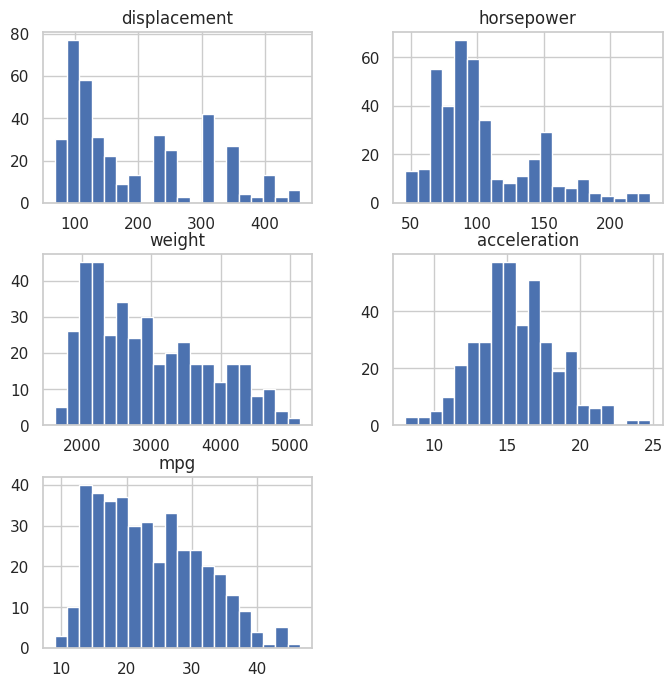

In [ ]:
# Check distribution of numerical columns
cat_cols = ['cylinders', 'model_year', 'origin']
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
num_cols = [col for col in num_cols if col not in cat_cols]

df[num_cols].hist(bins=20, figsize=(8,8))

Unique values in cylinders: [8 4 6 3 5]
Unique values in model_year: [70 71 72 73 74 75 76 77 78 79 80 81 82]
Unique values in origin: [1 3 2]


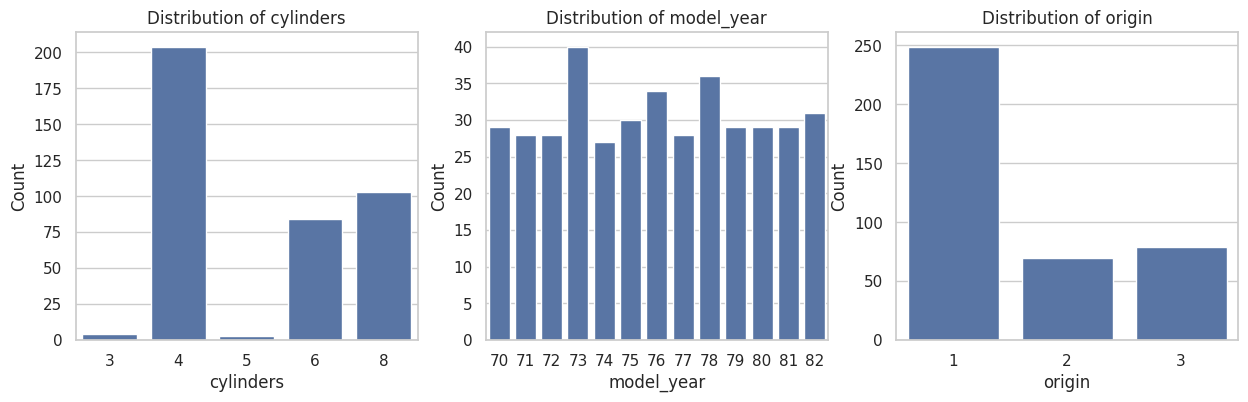

In [ ]:
# Check unique values in categorical columns
for col in cat_cols:
    print(f"Unique values in {col}: {df[col].unique()}")

# Check distributin of unque values in categorical columns
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(x=col, data=df, ax=axs[i])
    axs[i].set_title(f'Distribution of {col}')
    axs[i].set_xlabel(col)
    axs[i].set_ylabel('Count')

### 2.4. Multivariate analysis

Explore interactions among multiple features

<Axes: >

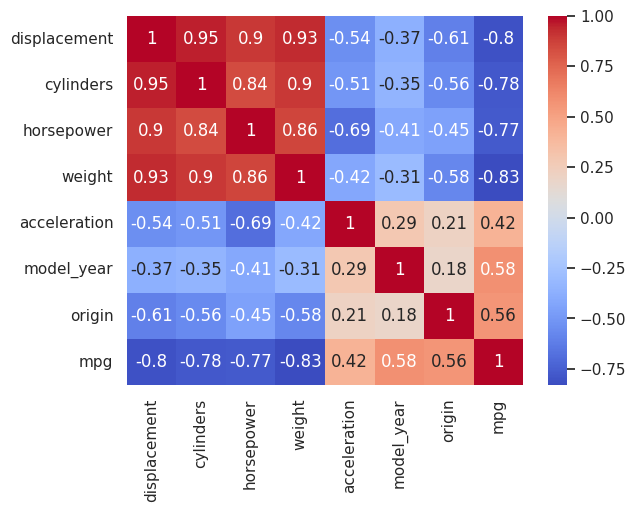

In [ ]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

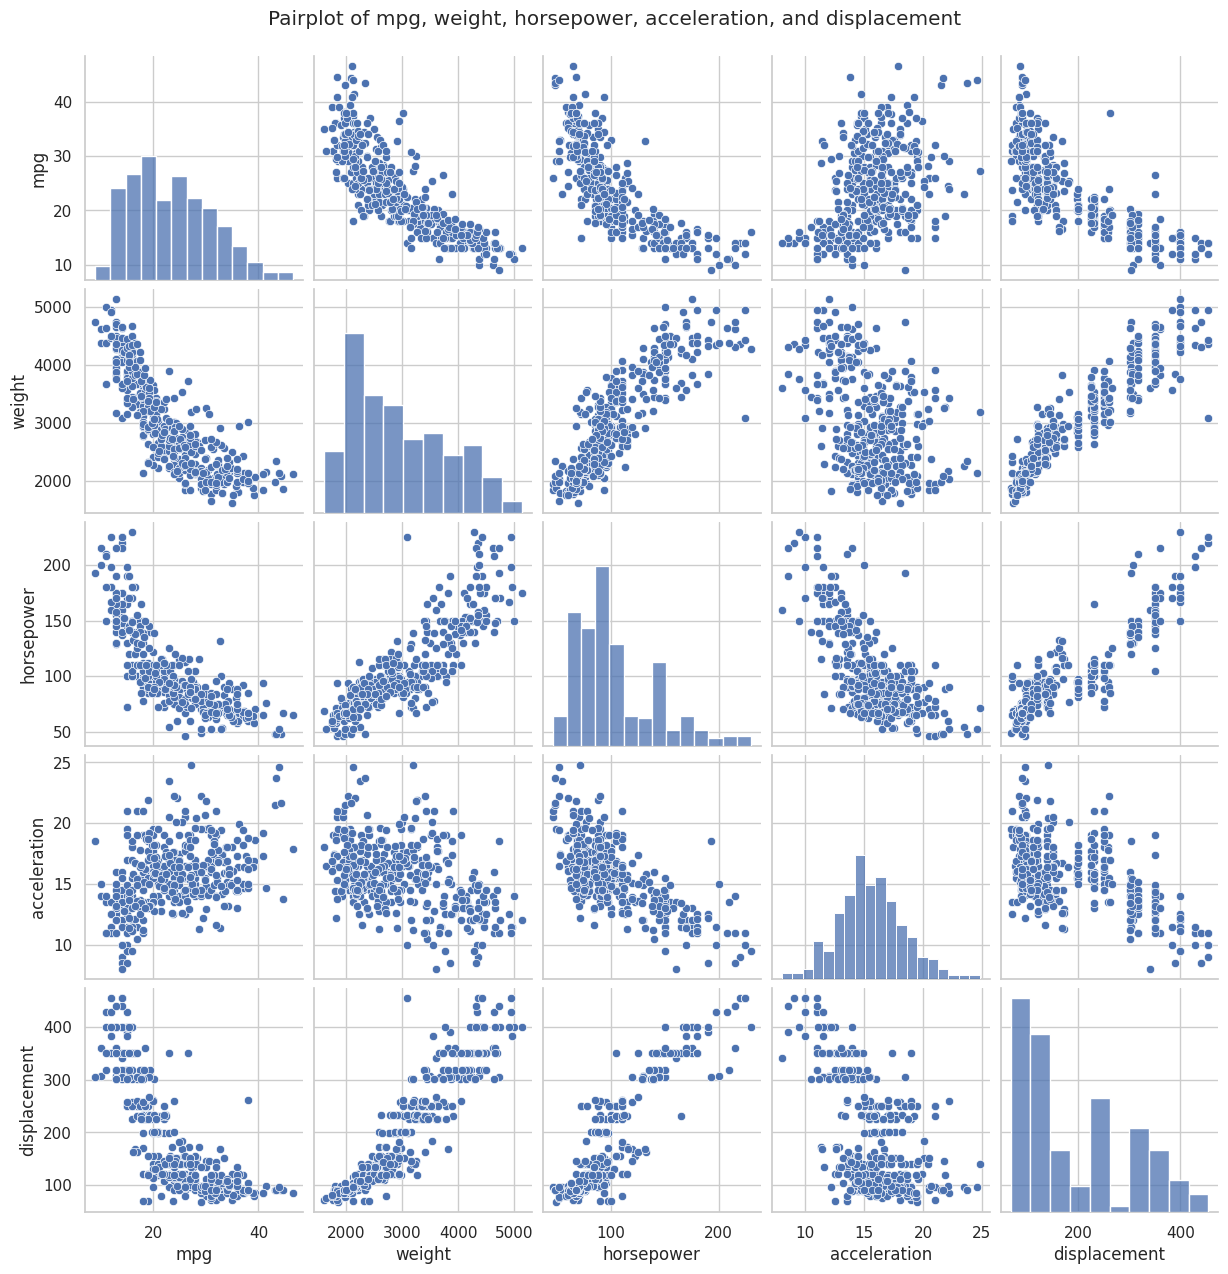

In [ ]:
# (a) Pairplot of selected features
cols_pair = ['mpg', 'weight', 'horsepower', 'acceleration', 'displacement']
sns.pairplot(df[cols_pair].dropna(), diag_kind='hist')
plt.suptitle("Pairplot of mpg, weight, horsepower, acceleration, and displacement", y=1.02)
plt.show()

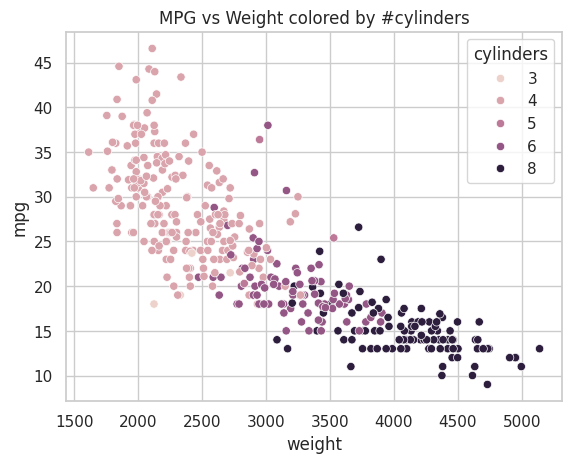

In [ ]:
# (b) Scatter: mpg vs weight, colored by cylinders
sns.scatterplot(
    data=df,
    x='weight',
    y='mpg',
    hue='cylinders',
)
plt.title("MPG vs Weight colored by #cylinders")
plt.show()

## 3. Feature engineering

In [ ]:
# 1. Handle missing values (fill NaN in horsepower with median)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# 2. Make categorical features numeric using One-Hot Encoding
# 'origin' and 'cylinders' are categorical, not continuous numbers
df_encoded = pd.get_dummies(df, columns=['origin', 'cylinders'], drop_first=True)

# 3. Select features (X) and target (y)
X = df_encoded.drop(columns='mpg')
y = df_encoded['mpg']

print("X shape:", X.shape)
print("Columns:", X.columns.tolist())

X shape: (398, 11)
Columns: ['displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_2', 'origin_3', 'cylinders_4', 'cylinders_5', 'cylinders_6', 'cylinders_8']


## 4. Model training

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalize values to the same range (fit ONLY on train to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression

# Create a LinearRegression model instance and fit the model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


## 5. Evaluatation

In [ ]:
# Predicting on the test set using the fitted model
y_pred = model.predict(X_test_scaled)

print("First 5 predictions:", y_pred[:5])

First 5 predictions: [33.2334447  29.94149413 19.42758886 17.35836574 13.31668746]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)  # Root Mean Squared Error
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

MAE:  2.1259
MSE:  7.2216
RMSE: 2.6873
R2 Score: 0.8657
